Bro 😎🔥 let's learn Morphological Operations in OpenCV with visual examples, intuition, and Python code. These operations are especially useful in your document-enhancement project for removing tiny noise spots, repairing broken text, and refining binary images.

# 1. What is morphology?

Morphology is a group of image-processing operations that analyze or modify the shapes of objects in an image.

It is commonly applied to binary images:

- White pixels (`255`) represent foreground objects, such as text.
- Black pixels (`0`) represent the background.

Morphological operations use a small shape called a structuring element (also called a kernel) to decide how neighboring pixels affect each other.

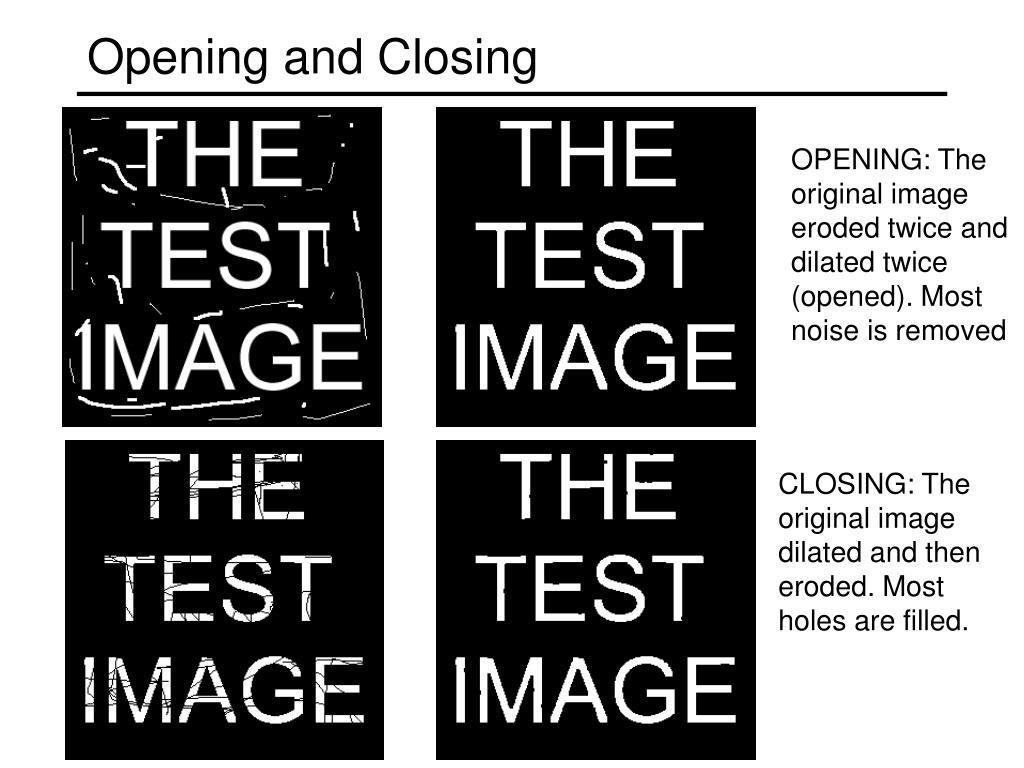

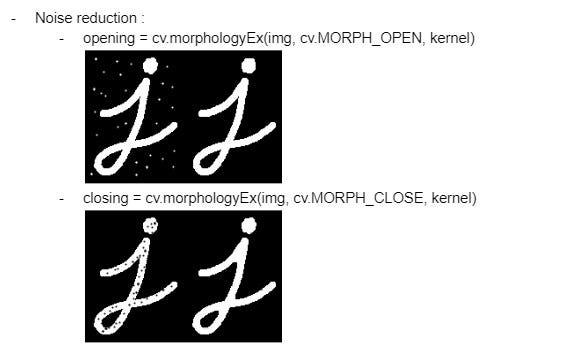
## The five operations

| Operation              | Main effect                      |
| ---------------------- | -------------------------------- |
| Erosion                | Shrinks white foreground objects |
| Dilation               | Expands white foreground objects |
| Opening                | Erosion followed by dilation     |
| Closing                | Dilation followed by erosion     |
| Morphological gradient | Highlights object boundaries     |

## 2. Erosion

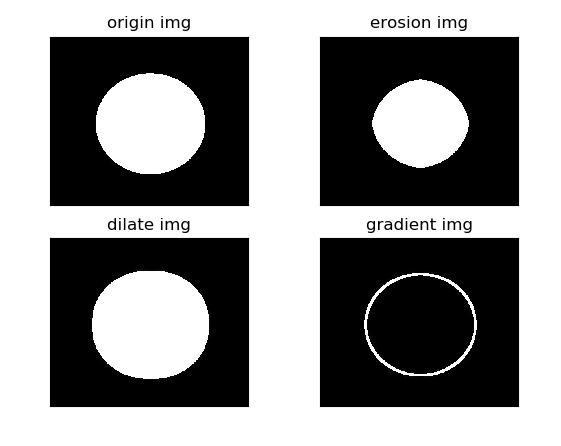

Idea: shrink the white foreground by removing pixels around its boundaries.

- Makes text strokes thinner.
- Can remove tiny white noise spots.
- May break thin connections between objects.

```
kernel = np.ones((3, 3), np.uint8)eroded = cv2.erode(binary, kernel, iterations=1)
```

OpenCV checks the neighborhood defined by the kernel. For a binary image, a foreground pixel survives only when the structuring element fits within the foreground at that position.


Document example: erosion can remove tiny white specks, but excessive erosion can destroy thin letters such as `i`, `l`, and `t`.

## 3. Dilation

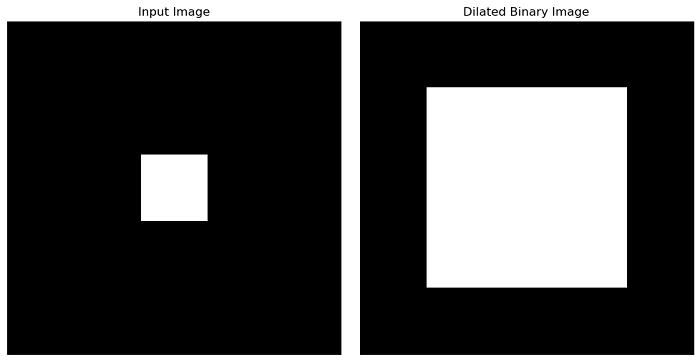


Idea: expand the white foreground by adding pixels around its boundaries.

- Makes text strokes thicker.
- Can connect nearby broken strokes.
- May join letters that are too close together.

```
dilated = cv2.dilate(binary, kernel, iterations=1)
```

Dilation expands foreground regions according to the size and shape of the kernel.

Document example: dilation can help repair small gaps in broken characters, but excessive dilation can merge adjacent characters.

## 4. Opening

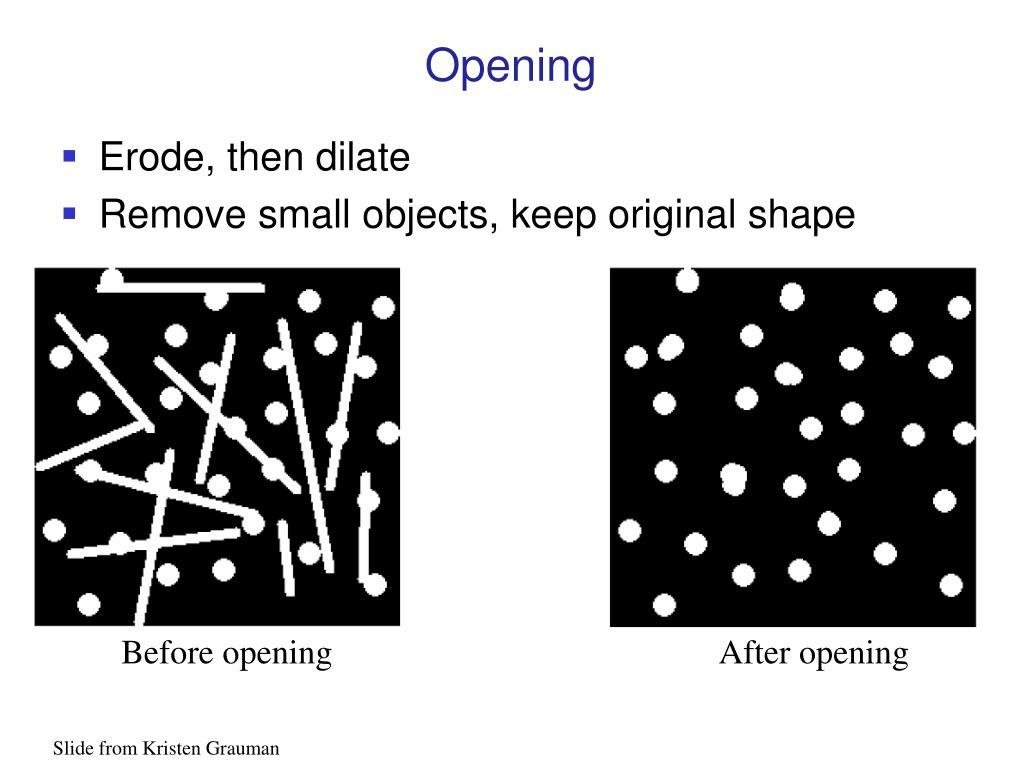


Idea: erosion followed by dilation.

\\[ \text{Opening}=\text{Dilation}(\text{Erosion}(I)) \\]

- Removes small white foreground specks.
- Helps preserve larger foreground structures.
- Can damage thin text strokes if the kernel is too large.

```
opening = cv2.morphologyEx(    binary, cv2.MORPH_OPEN, kernel)
```

Remember: opening is especially useful when unwanted noise consists of small white objects on a black background.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://docs.opencv.org\&sz=32)

OpenCV Documentation+1



## 5. Closing

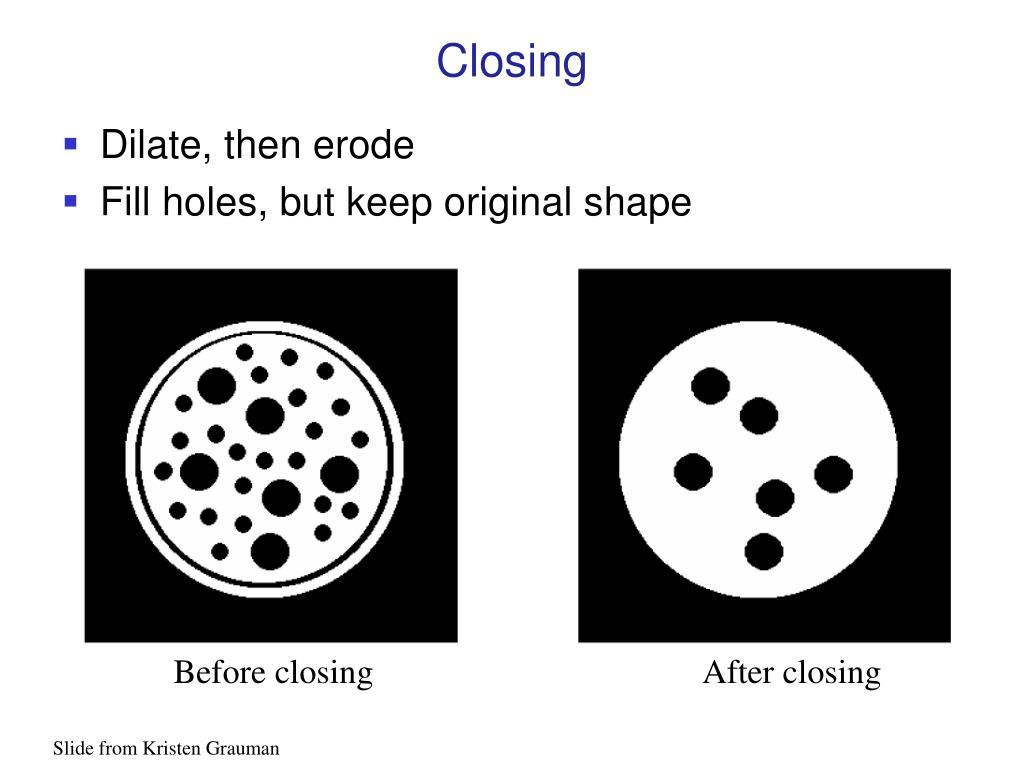


Idea: dilation followed by erosion.

\\[ \text{Closing}=\text{Erosion}(\text{Dilation}(I)) \\]

- Fills small black holes inside white objects.
- Can bridge small gaps in text strokes.
- May merge nearby characters or objects.

```
closing = cv2.morphologyEx(    binary, cv2.MORPH_CLOSE, kernel)
```

Remember: closing is useful for small dark gaps or holes within the foreground.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://docs.opencv.org\&sz=32)

OpenCV Documentation+1



## 6. Morphological gradient

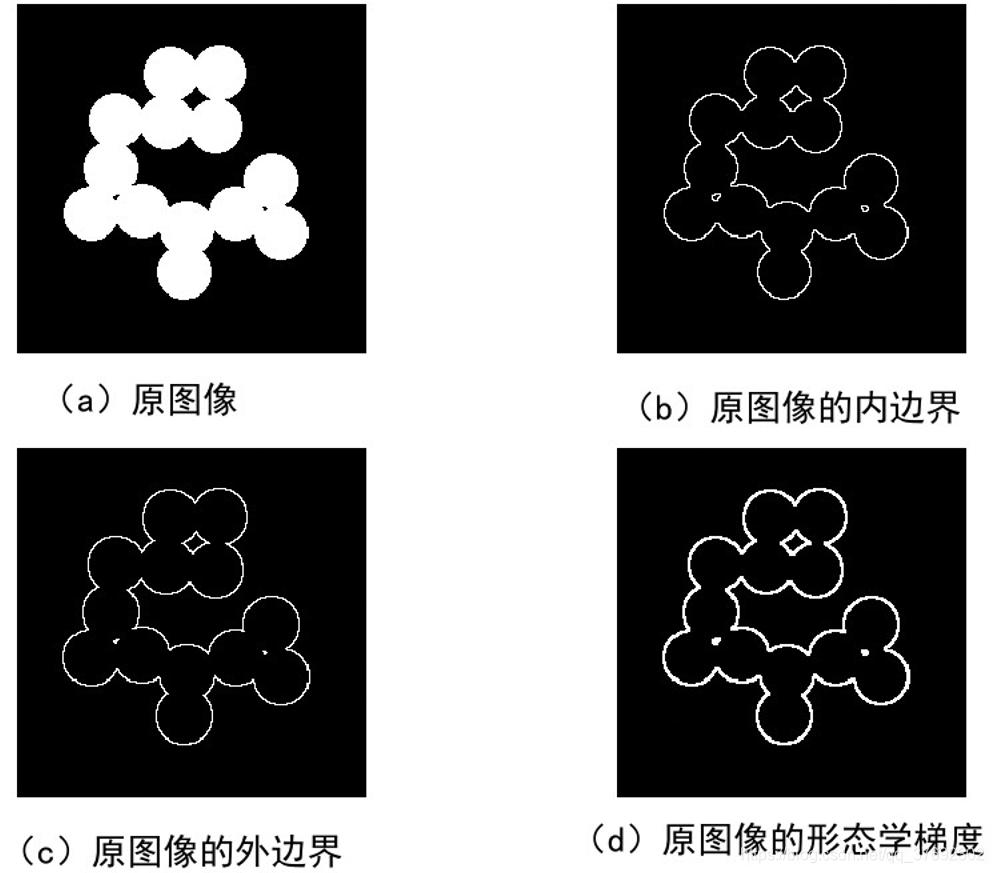


Idea: subtract the eroded image from the dilated image.

\\[ G=\text{Dilation}(I)-\text{Erosion}(I) \\]

- Highlights the boundaries of objects.
- Produces outline-like edges.
- Useful for shape and contour analysis.

```
gradient = cv2.morphologyEx(    binary, cv2.MORPH_GRADIENT, kernel)
```

Unlike Sobel and Canny, the morphological gradient derives boundaries from the difference between dilation and erosion


## 8. Quick revision

| Operation              | Order          | Main purpose                   |
| ---------------------- | -------------- | ------------------------------ |
| Erosion                | Erode          | Shrink white objects           |
| Dilation               | Dilate         | Expand white objects           |
| Opening                | Erode → Dilate | Remove small white noise       |
| Closing                | Dilate → Erode | Fill small dark holes and gaps |
| Morphological gradient | Dilate − Erode | Extract object outlines        |

---

## Why Convert Grayscale to Binary?

**Purpose:** Separate foreground objects (text or shapes) from the background.

- Grayscale images contain intensity values from `0–255`.
- Binary thresholding converts pixels into only `0` (black) or `255` (white).
- Otsu's method automatically selects a suitable global threshold.
- Binary images make morphological operations easier to control.

**Applications:**
- Erosion: shrink foreground objects.
- Dilation: expand foreground objects.
- Opening: remove small white noise.
- Closing: fill small black gaps.

**Important:** Binary conversion is not mandatory for morphology. It is useful when processing distinct foreground shapes, such as text on a document.

```python
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
```

**Remember:** Grayscale represents intensity; binary thresholding separates foreground and background.

## Morphological Iterations

**Definition:** `iterations` specifies how many times a morphological operation is repeated.

- Each iteration uses the previous iteration's output as its input.
- **Erosion:** Increasing iterations shrinks white foreground objects further.
- **Dilation:** Increasing iterations expands white foreground objects further.
- **Opening:** Repeats erosion followed by dilation.
- **Closing:** Repeats dilation followed by erosion.

**Example:**
```python
result = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=3
)
```

Here, opening is repeated three times using the specified kernel.

**Important:** Increasing iterations strengthens the effect but may damage object shapes or remove useful details. The first iteration may produce only subtle changes.

**Remember:** Each iteration processes the previous result, not the original image independently.

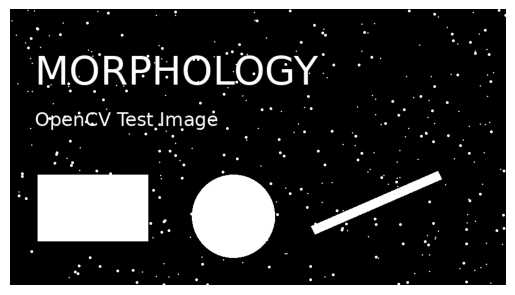

In [1]:
import cv2
import matplotlib.pyplot as plt 
import numpy as np 

image_path = 'images/3_Morphology/Raw/02_white_speckle_noise.png'
image = cv2.imread(image_path)
gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)

plt.imshow(gray,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.show()

In [2]:
_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (3, 3)
)

print("Kernel:\n", kernel)

Kernel:
 [[1 1 1]
 [1 1 1]
 [1 1 1]]


# Erosion

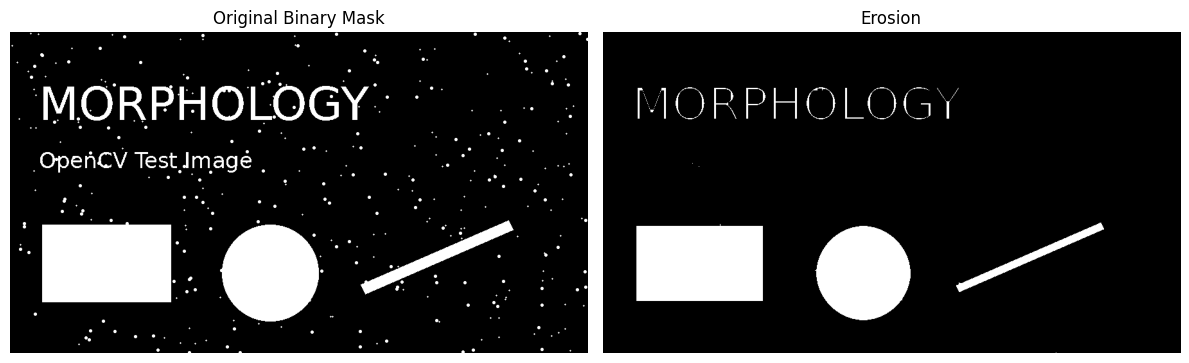

In [3]:
eroded = cv2.erode(
    binary,
    kernel,
    iterations=2
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(binary, cmap="gray")
axes[0].set_title("Original Binary Mask")

axes[1].imshow(eroded, cmap="gray")
axes[1].set_title("Erosion")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

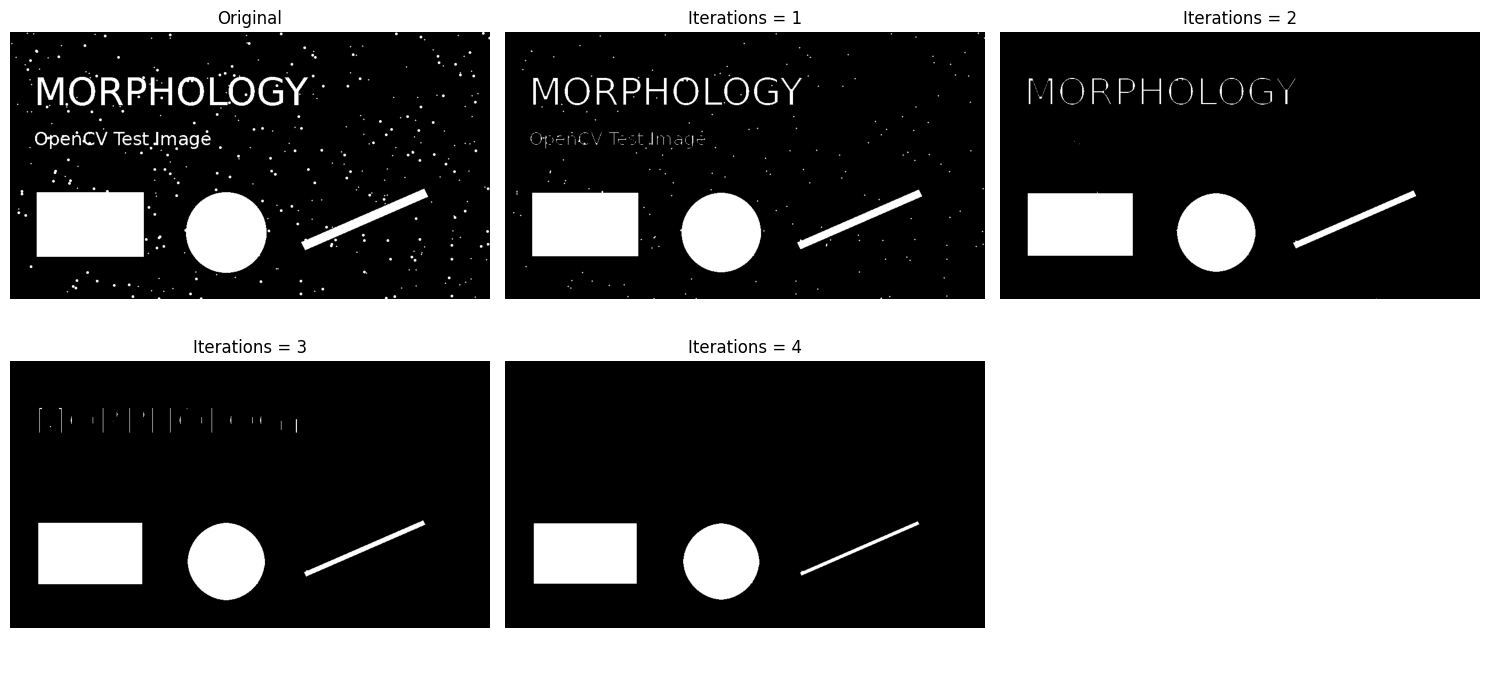

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

plt.subplot(2,3,1)
plt.imshow(binary,cmap='gray')
plt.title('Original')
plt.axis('off')

for ax, iterations in zip([2, 3, 4, 5], [1, 2, 3, 4]):
    result = cv2.erode(
        binary, kernel, iterations=iterations
    )

    plt.subplot(2,3,ax)
    plt.imshow(result, cmap="gray")
    plt.title(f"Iterations = {iterations}")
    plt.axis("off")

plt.subplot(2,3,6)
plt.axis('off')

plt.tight_layout()
plt.savefig('images/3_Morphology/Processed/1.Erosion.jpg')
plt.show()

# Dilation

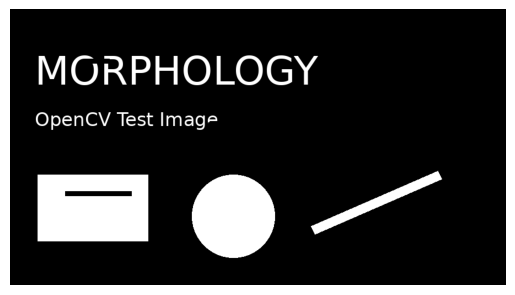

In [5]:
image_path = 'images/3_Morphology/Raw/03_broken_strokes.png'
image = cv2.imread(image_path)
gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)

plt.imshow(gray,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.show()

_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

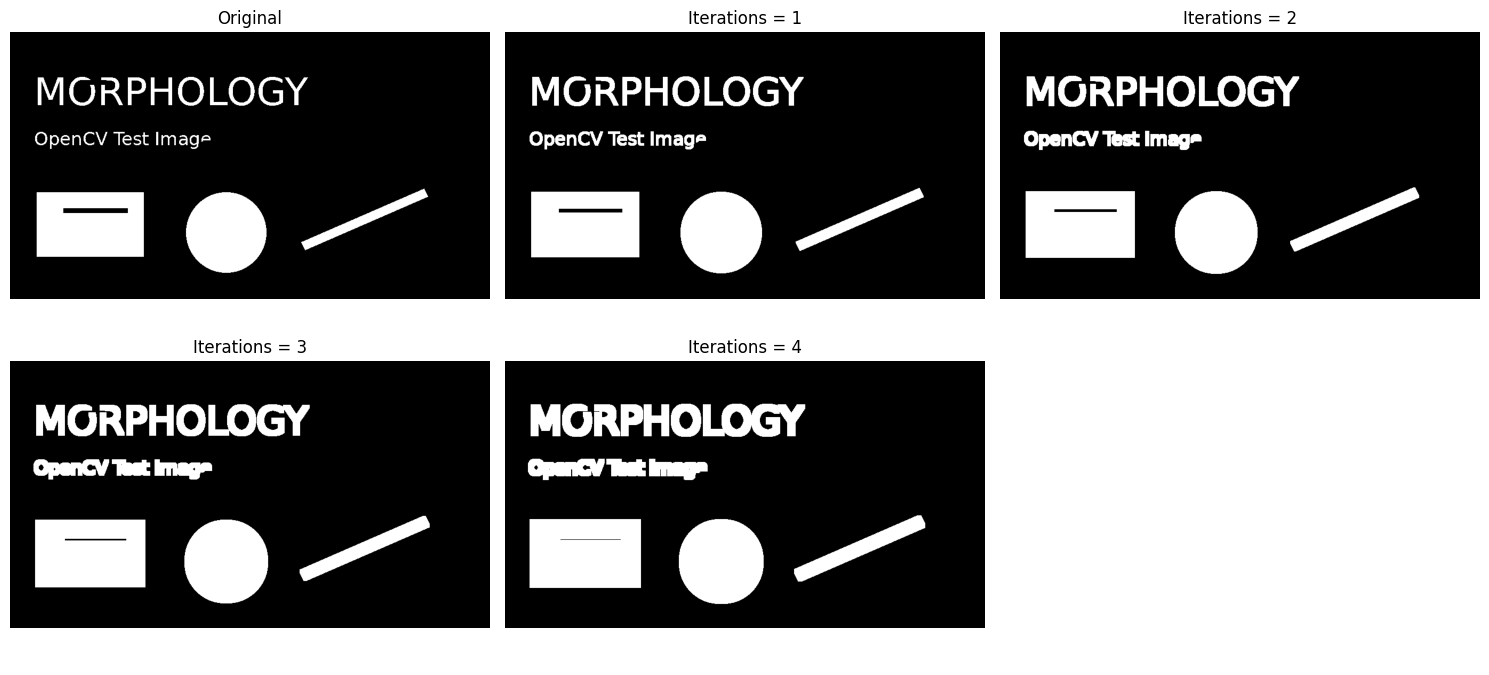

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

plt.subplot(2,3,1)
plt.imshow(binary,cmap='gray')
plt.title('Original')
plt.axis('off')

for ax, iterations in zip([2, 3, 4, 5], [1, 2, 3, 4]):
    result = cv2.dilate(
        binary, kernel, iterations=iterations
    )

    plt.subplot(2,3,ax)
    plt.imshow(result, cmap="gray")
    plt.title(f"Iterations = {iterations}")
    plt.axis("off")

plt.subplot(2,3,6)
plt.axis('off')

plt.tight_layout()
plt.savefig('images/3_Morphology/Processed/2.Dilation.jpg')
plt.show()

# Opening

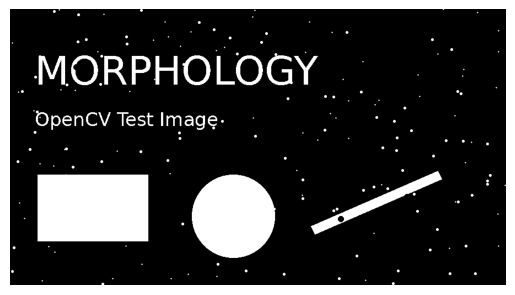

In [7]:
image_path = 'images/3_Morphology/Raw/05_mixed_specks_and_holes.png'
image = cv2.imread(image_path)
gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.imshow(binary,cmap='gray')
plt.axis('off')
plt.show()

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (3, 3)
)

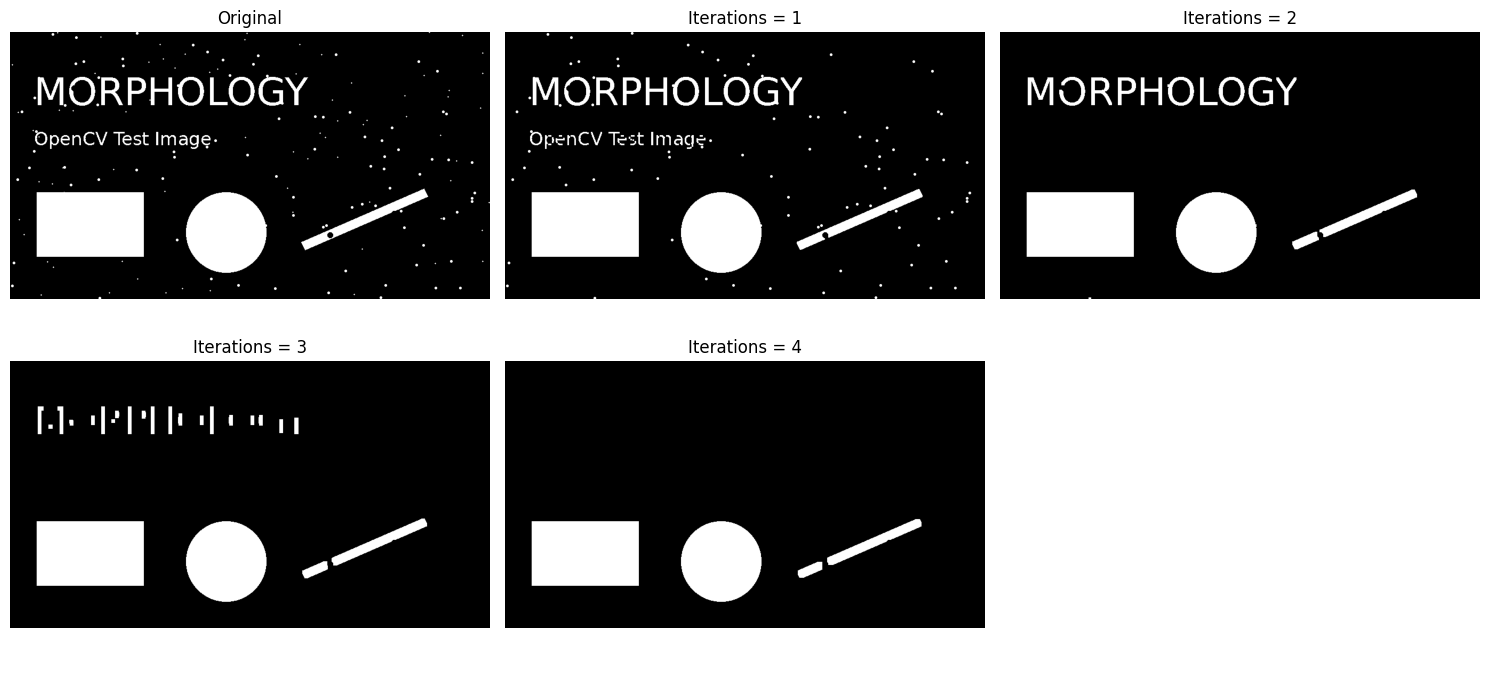

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

plt.subplot(2,3,1)
plt.imshow(binary,cmap='gray')
plt.title('Original')
plt.axis('off')

for ax, iterations in zip([2, 3, 4, 5], [1, 2, 3, 4]):
    result = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel,
        iterations= iterations
    )

    plt.subplot(2,3,ax)
    plt.imshow(result, cmap="gray")
    plt.title(f"Iterations = {iterations}")
    plt.axis("off")

plt.subplot(2,3,6)
plt.axis('off')

plt.tight_layout()
plt.savefig('images/3_Morphology/Processed/3.Opening.jpg')
plt.show()

# Closing

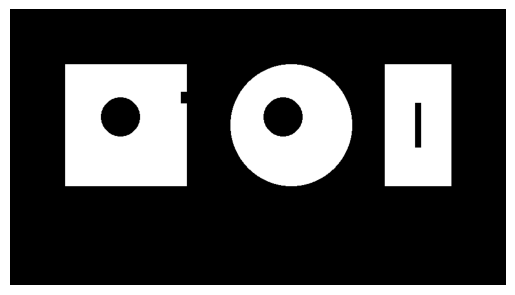

In [9]:
image_path = 'images/3_Morphology/Raw/04_holes_and_gaps.png'
image = cv2.imread(image_path)
gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.imshow(binary,cmap='gray')
plt.axis('off')
plt.show()

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (7, 7)
)

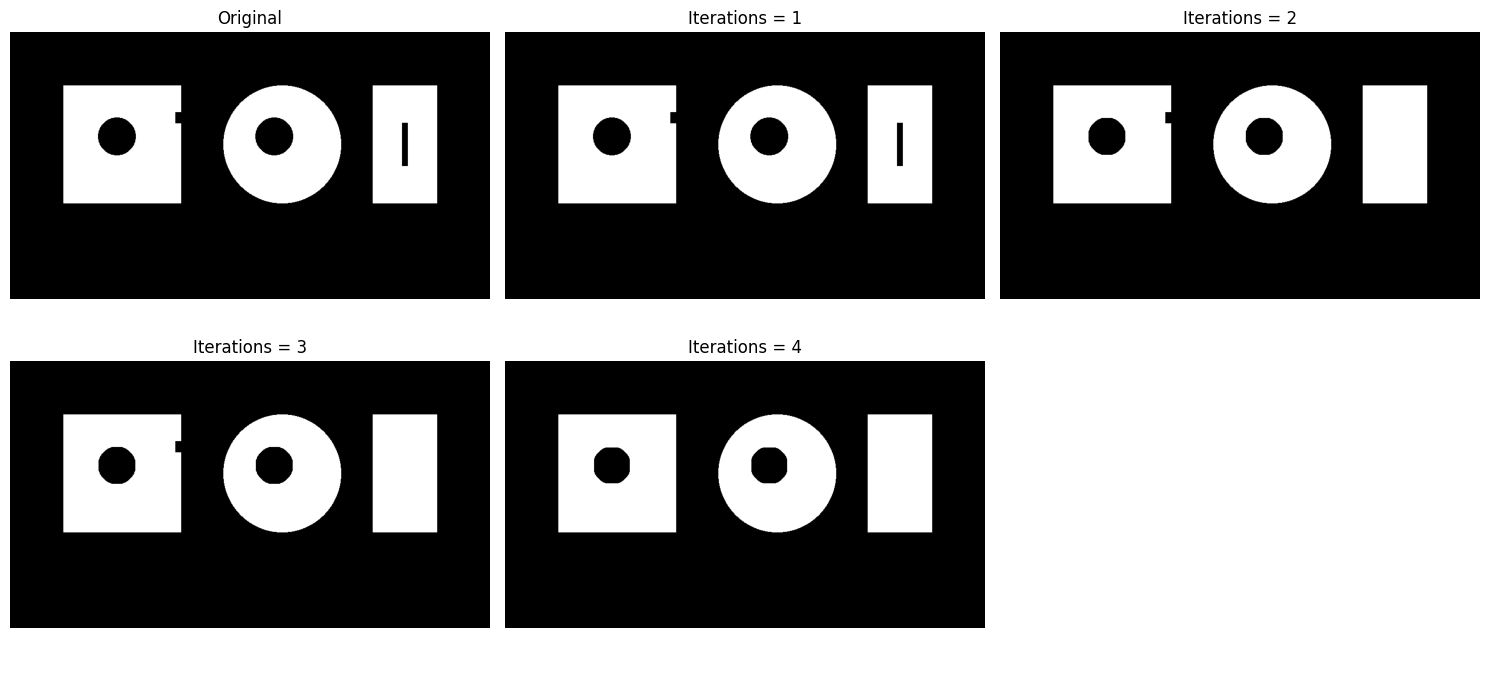

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

plt.subplot(2,3,1)
plt.imshow(binary,cmap='gray')
plt.title('Original')
plt.axis('off')

for ax, iterations in zip([2, 3, 4, 5], [1, 2, 3, 4]):
    result = cv2.morphologyEx(
        binary,
        cv2.MORPH_CLOSE,
        kernel,
        iterations= iterations
    )

    plt.subplot(2,3,ax)
    plt.imshow(result, cmap="gray")
    plt.title(f"Iterations = {iterations}")
    plt.axis("off")

plt.subplot(2,3,6)
plt.axis('off')

plt.tight_layout()
plt.savefig('images/3_Morphology/Processed/4.closing.jpg')
plt.show()

# Morphological gradient

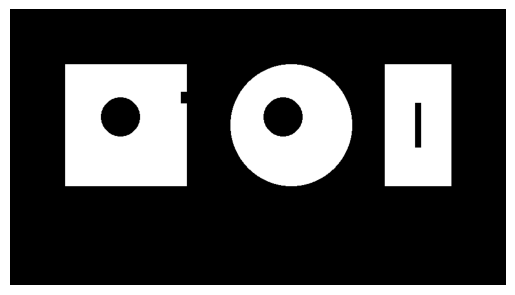

In [11]:
image_path = 'images/3_Morphology/Raw/04_holes_and_gaps.png'
image = cv2.imread(image_path)
gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.imshow(binary,cmap='gray')
plt.axis('off')
plt.show()

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (3, 3)
)

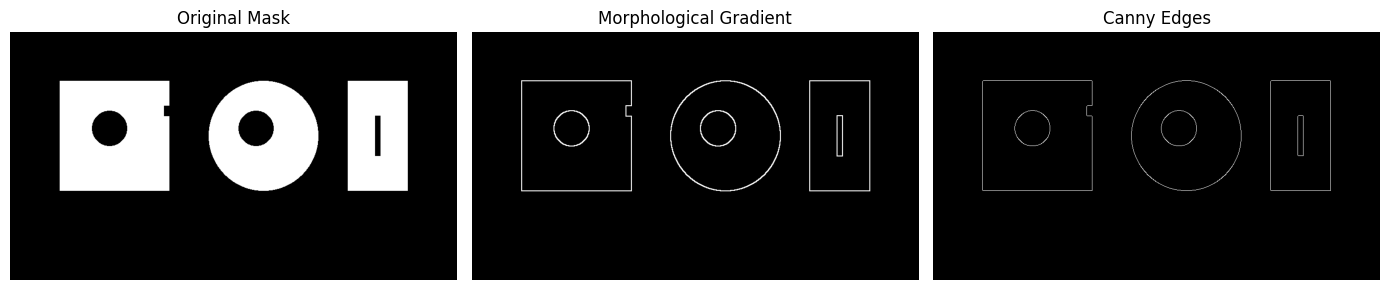

In [12]:
morph_gradient = cv2.morphologyEx(
    binary,
    cv2.MORPH_GRADIENT,
    kernel
)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, (img, title) in zip(
    axes,
    [
        (binary, "Original Mask"),
        (morph_gradient, "Morphological Gradient"),
        (cv2.Canny(gray, 100, 200), "Canny Edges")
    ]
):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig('images/3_Morphology/Processed/5.Morphological Gradient.jpg')
plt.show()